# Lahore air quality: how much do wind and humidity explain PM2.5?

Data: 30 days of hourly PM2.5 from 5 OpenAQ stations in Lahore (Oct 19 to Nov 18, 2026), matched to hourly weather from Open-Meteo.
All times are converted to Pakistan time (UTC+5) for the charts.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.titleweight": "bold", "axes.titlesize": 12})

Path("figures").mkdir(exist_ok=True)

d = pd.read_csv("../data/history.csv", parse_dates=["time_utc"])
d["local"] = d["time_utc"].dt.tz_convert("Asia/Karachi")   # Pakistan time
d["hour"] = d["local"].dt.hour
d["date"] = d["local"].dt.date
print(d.shape)
d.head()

(2697, 10)


,time_utc,pm25,station_id,station_name,temperature_c,humidity_pct,wind_kmh,local,hour,date
0,2026-10-19 08:00:00+00:00,40.8,4555745,Ravi Road,29.5,45,6.2,2026-10-19 13:00:00+05:00,13,2026-10-19
1,2026-10-19 09:00:00+00:00,42.9,4555745,Ravi Road,29.6,44,6.9,2026-10-19 14:00:00+05:00,14,2026-10-19
2,2026-10-19 10:00:00+00:00,45.6,4555745,Ravi Road,29.4,44,7.4,2026-10-19 15:00:00+05:00,15,2026-10-19
3,2026-10-19 11:00:00+00:00,50.0,4555745,Ravi Road,28.7,50,6.0,2026-10-19 16:00:00+05:00,16,2026-10-19
4,2026-10-19 12:00:00+00:00,59.6,4555745,Ravi Road,27.7,58,6.1,2026-10-19 17:00:00+05:00,17,2026-10-19


## 1. Data audit

Three checks: **missing hours**, **stuck values** (the same number repeated, a sign of a frozen sensor) and **spikes**.

In [2]:
# Missing hours: a full 30 days is about 719 hourly readings per station
window = pd.date_range(d["time_utc"].min(), d["time_utc"].max(), freq="h")
rows = []
for name, g in d.sort_values("time_utc").groupby("station_name"):
    gaps = g["time_utc"].diff().dt.total_seconds() / 3600
    rows.append({
        "station": name,
        "readings": len(g),
        "coverage_%": round(len(g) / len(window) * 100),
        "gaps_over_1h": int((gaps > 1).sum()),
        "longest_gap_hours": int(gaps.max()),
    })
audit = pd.DataFrame(rows).sort_values("coverage_%")
audit

,station,readings,coverage_%,gaps_over_1h,longest_gap_hours
3,Shalimar Town,256,36,20,279
4,Thokar Niaz Baig,367,51,11,189
2,Ravi Road,661,92,5,54
0,Cantonment,694,97,3,2
1,Gulberg III,719,100,0,1


In [3]:
# Stuck values: 4 or more identical readings in a row
def longest_run(values):
    best = run = 1
    for a, b in zip(values[:-1], values[1:]):
        run = run + 1 if a == b else 1
        best = max(best, run)
    return best

for name, g in d.sort_values("time_utc").groupby("station_name"):
    print(f"{name}: longest run of identical values = {longest_run(g['pm25'].tolist())}")

# Impossible values
print("\nReadings <= 0:", (d["pm25"] <= 0).sum())
print("Highest reading:", d["pm25"].max())

Cantonment: longest run of identical values = 2
Gulberg III: longest run of identical values = 2
Ravi Road: longest run of identical values = 2
Shalimar Town: longest run of identical values = 1
Thokar Niaz Baig: longest run of identical values = 2

Readings <= 0: 0
Highest reading: 516.0


In [4]:
# Spikes: a reading more than 2x its local median (7-hour window) and above 100
spike_rows = []
for name, g in d.sort_values("time_utc").groupby("station_name"):
    med = g["pm25"].rolling(7, center=True, min_periods=3).median()
    s = g[(g["pm25"] / med > 2) & (g["pm25"] > 100)]
    spike_rows.append({"station": name, "spikes": len(s)})
pd.DataFrame(spike_rows)

,station,spikes
0,Cantonment,0
1,Gulberg III,1
2,Ravi Road,4
3,Shalimar Town,3
4,Thokar Niaz Baig,1


**Audit findings (draft, edit in your own words):**
- No stuck values and no impossible readings (zero or negative).
- Gulberg III (100%), Cantonment (97%) and Ravi Road (92%) are close to complete.
- Shalimar Town (36%) and Thokar Niaz Baig (51%) are missing most of their readings, with long gaps (up to about 11 days and 8 days).
- Spikes are rare (a handful across all stations), so I kept them.

## 2. Summary statistics

In [5]:
stats = d.groupby("station_name")["pm25"].agg(["count", "mean", "median", "std", "min", "max"]).round(1)
print(stats)
print()
print(d["pm25"].describe().round(1))
print()
print(f"Readings above 150 ug/m3: {(d['pm25'] > 150).mean():.0%}")
print(f"Readings above 250 ug/m3: {(d['pm25'] > 250).mean():.0%}")

                  count   mean  median   std   min    max
station_name                                             
Cantonment          694  163.3   153.5  86.7  12.5  516.0
Gulberg III         719  177.9   169.0  86.2  12.5  454.0
Ravi Road           661  143.3   134.0  77.0  24.9  410.0
Shalimar Town       256  144.5   132.0  79.5  31.3  374.0
Thokar Niaz Baig    367  154.5   153.0  76.9  30.2  427.0

count    2697.0
mean      159.3
std        83.3
min        12.5
25%        89.1
50%       150.0
75%       221.0
max       516.0
Name: pm25, dtype: float64

Readings above 150 ug/m3: 50%
Readings above 250 ug/m3: 15%


## 3. Charts

### Chart 1: daily average PM2.5
The first and last dates are partial days, so they are left out.

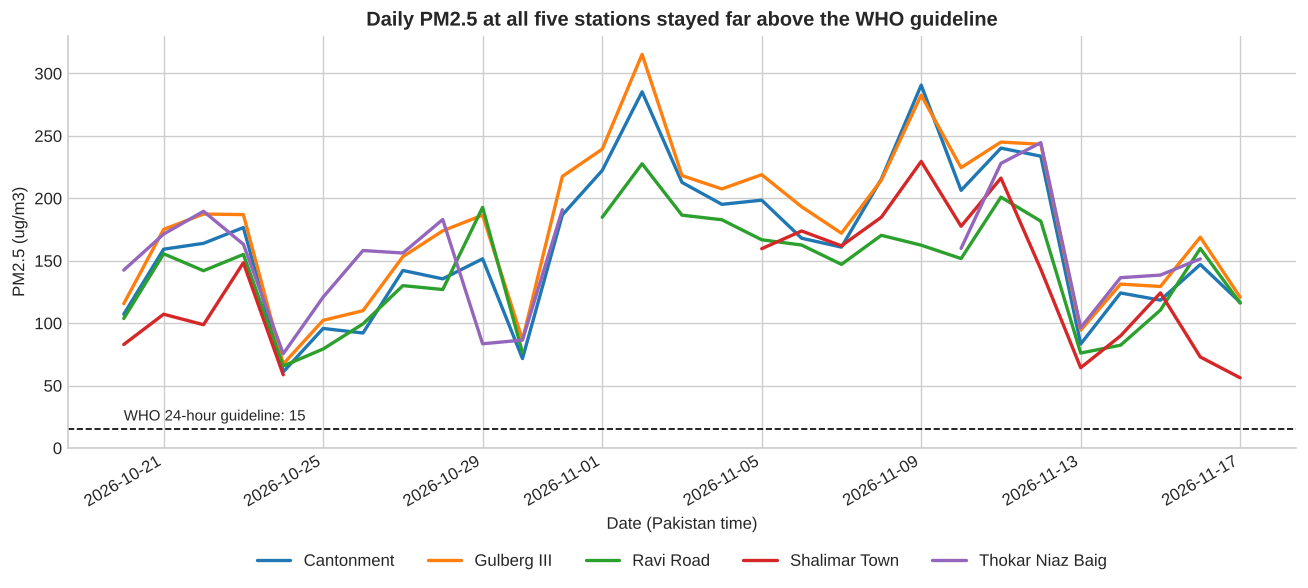

In [6]:
daily = d.groupby(["date", "station_name"])["pm25"].mean().unstack()
daily = daily.iloc[1:-1]   # drop partial first and last day

fig, ax = plt.subplots(figsize=(11, 5))
for col in daily.columns:
    ax.plot(daily.index, daily[col], lw=2, label=col)
ax.axhline(15, color="black", ls="--", lw=1)
ax.text(daily.index[0], 22, "WHO 24-hour guideline: 15", fontsize=9)
ax.set_title("Daily PM2.5 at all five stations stayed far above the WHO guideline")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.set_xlabel("Date (Pakistan time)")
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22))
ax.spines[["top", "right"]].set_visible(False)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig("figures/1_daily_pm25.png", bbox_inches="tight")
plt.show()

**Reading (draft):** Every day's average was far above the WHO guideline of 15, and the stations rise and fall together, which suggests citywide weather matters more than local sources.

### Chart 2: PM2.5 by hour of day

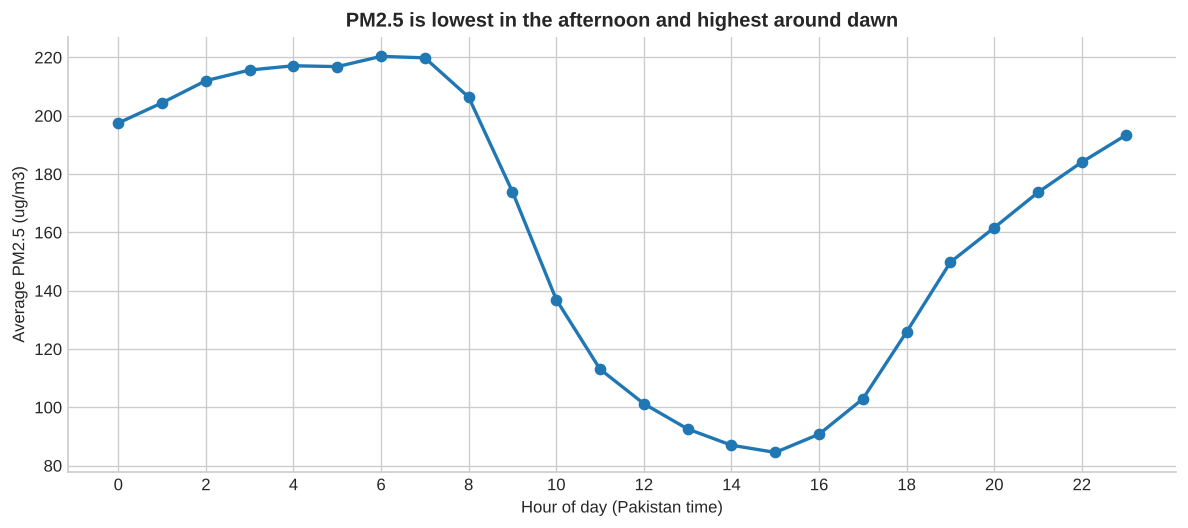

{0: 197.0, 1: 204.0, 2: 212.0, 3: 216.0, 4: 217.0, 5: 217.0, 6: 220.0, 7: 220.0, 8: 206.0, 9: 174.0, 10: 137.0, 11: 113.0, 12: 101.0, 13: 93.0, 14: 87.0, 15: 84.0, 16: 91.0, 17: 103.0, 18: 126.0, 19: 150.0, 20: 162.0, 21: 174.0, 22: 184.0, 23: 193.0}


In [7]:
hod = d.groupby("hour")["pm25"].mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(hod.index, hod.values, marker="o", lw=2)
ax.set_title("PM2.5 is lowest in the afternoon and highest around dawn")
ax.set_xlabel("Hour of day (Pakistan time)")
ax.set_ylabel("Average PM2.5 (ug/m3)")
ax.set_xticks(range(0, 24, 2))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/2_hour_of_day.png", bbox_inches="tight")
plt.show()
print(hod.round(0).to_dict())

**Reading (draft):** Pollution peaks around 6 to 7 AM (about 220) and bottoms out near 3 PM (about 84), so time of day alone swings PM2.5 by a factor of more than two.

### Chart 3: how complete is each station?

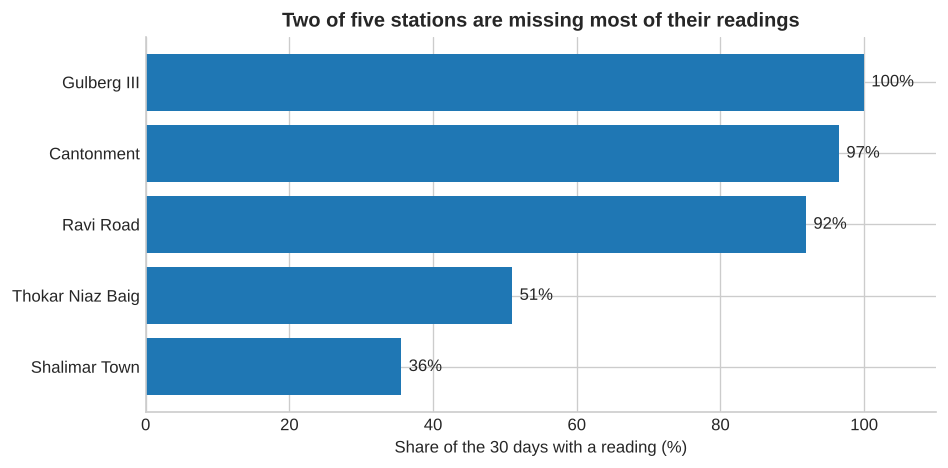

In [8]:
cov = (d.groupby("station_name").size() / len(window) * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(cov.index, cov.values)
for b, v in zip(bars, cov.values):
    ax.text(v + 1, b.get_y() + b.get_height() / 2, f"{v:.0f}%", va="center")
ax.set_xlim(0, 110)
ax.set_xlabel("Share of the 30 days with a reading (%)")
ax.set_title("Two of five stations are missing most of their readings")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/3_coverage.png", bbox_inches="tight")
plt.show()

**Reading (draft):** Only three stations have close to full data, so any city-wide number leans on Gulberg III, Cantonment and Ravi Road.

## 4. Regression: PM2.5 on wind and humidity

Weather is the same for the whole city, so I average the stations into **one city value per hour**. That avoids counting the same weather several times.
Hourly data is correlated from one hour to the next, so the standard errors use a correction (HAC) for that.

In [9]:
city = d.groupby("time_utc").agg(
    pm25=("pm25", "mean"),
    wind=("wind_kmh", "first"),
    hum=("humidity_pct", "first"),
    temp=("temperature_c", "first"),
    hour=("hour", "first"),
    n_stations=("pm25", "size"),
).reset_index()

print("Hours:", len(city))
print(city[["pm25", "wind", "hum", "temp"]].corr().round(2))

Hours: 719
      pm25  wind   hum  temp
pm25  1.00 -0.26  0.61 -0.54
wind -0.26  1.00 -0.18  0.14
hum   0.61 -0.18  1.00 -0.84
temp -0.54  0.14 -0.84  1.00


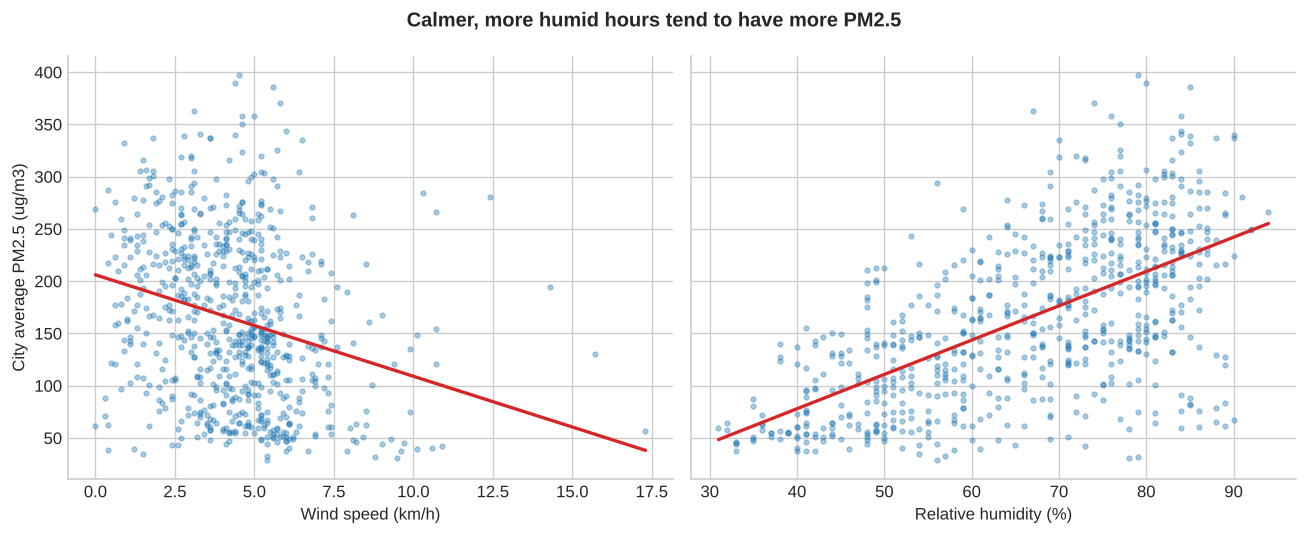

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, col, label in zip(axs, ["wind", "hum"], ["Wind speed (km/h)", "Relative humidity (%)"]):
    ax.scatter(city[col], city["pm25"], s=8, alpha=0.35)
    slope, intercept = np.polyfit(city[col], city["pm25"], 1)
    xs = np.linspace(city[col].min(), city[col].max(), 50)
    ax.plot(xs, slope * xs + intercept, color="C3", lw=2)
    ax.set_xlabel(label)
    ax.spines[["top", "right"]].set_visible(False)
axs[0].set_ylabel("City average PM2.5 (ug/m3)")
fig.suptitle("Calmer, more humid hours tend to have more PM2.5", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/4_scatter.png", bbox_inches="tight")
plt.show()

**Reading (draft):** Higher humidity goes with more PM2.5 and higher wind goes with less, and humidity shows the clearer pattern.

In [11]:
m1 = smf.ols("pm25 ~ wind + hum", data=city).fit(cov_type="HAC", cov_kwds={"maxlags": 24})
print(m1.summary().tables[1])
print("R-squared:", round(m1.rsquared, 2), " hours:", int(m1.nobs))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -18.7979     21.844     -0.861      0.389     -61.612      24.016
wind          -5.7274      2.211     -2.590      0.010     -10.062      -1.393
hum            3.1368      0.312     10.063      0.000       2.526       3.748
R-squared: 0.4  hours: 719


In [12]:
# Robustness check: add hour of day, because humidity is high at night
m2 = smf.ols("pm25 ~ wind + hum + C(hour)", data=city).fit(cov_type="HAC", cov_kwds={"maxlags": 24})
print(pd.DataFrame({"coef": m2.params[["wind", "hum"]], "p_value": m2.pvalues[["wind", "hum"]]}).round(3))
print("R-squared:", round(m2.rsquared, 2))

       coef  p_value
wind -6.597    0.012
hum   0.985    0.440
R-squared: 0.44


**What the regression says (draft):**
- Without time of day: each extra 1 km/h of wind goes with about 5.7 ug/m3 less PM2.5, and each extra point of humidity goes with about 3.1 ug/m3 more. The two together explain about 40% of the hour-to-hour variation (R-squared 0.40).
- With time of day added: the wind effect holds (about -6.6, p = 0.01), but the humidity effect shrinks to about 1.0 and is no longer clearly different from zero (p = 0.44). Humidity mostly tracks the time of day, so much of its first effect was really "night vs afternoon".

**Limits:** this shows association, not cause. Weather comes from a model, not a local station, and temperature and humidity are strongly linked (-0.84), so they are hard to separate. It covers 30 days in one season.